# Cross-dataset MSN integration — HD (Handsaker Village, optional DeepDive) + NucSeq + SlideTags — joint scVI/scANVI

**Strategy:** concatenate the datasets listed in `DATASETS` (Section 1) and train **one** scVI model (then scANVI on top) on all of them together — no reference/query split, every dataset gets equal weight.
This replaces the earlier scArches notebook (`01_integrate_HD_NucSeq_SlideTags_scArches.ipynb`), where HD was the reference and NucSeq+SlideTags were mapped on by surgery. Surgery only learns new batch embeddings for the query, so it cannot absorb a technology the reference never saw (SlideTags).

**Integration design (one model):**
`scVI(batch_key = "batch", categorical_covariate_keys = ["sex"])`, where `batch` = `<dataset>__<technical library unit>`.

| dataset | `batch` unit | pooling design (MSN cells) |
|---|---|---|
| HD | `reaction` (47) | Village pools: ~17 donors per reaction, each donor in ~8 reactions → donor **crossed** with batch |
| NucSeq | `library` (16) | ~16 donors (XDP + control) multiplexed per library, each donor in 4–8 libraries → donor **crossed** with batch |
| SlideTags | `library_id` (51) | one donor per library (one puck/sort), 3–8 libraries per donor → batch **nested** in donor |
| HD_deepdive (optional) | `reaction` (38) | one donor per reaction, 3–6 reactions per donor → batch **nested** in donor. All 9 donors (8 HD, 1 control, caudate) are also in HD Village, under the same `S#####` IDs |

Why only these covariates:
- **`dataset` is not added**: every `batch` level sits inside exactly one dataset, so the batch embedding already carries the dataset/technology effect.
- **`donor` is not added**: in HD/NucSeq donor is biology (and crossed with batch, so it stays in the latent space); in SlideTags/DeepDive it is aliased with the batch anyway.
- **SlideTags `Sorted` (NeUN+/Unsorted) is not added**: it is constant within each `library_id`, so the batch already absorbs it.
- SlideTags `library` (`SI-TT-H1`, …) is **not unique** — the same index is reused across sequencing runs — so `library_id` (run + index) is the batch unit.

Consequence to keep in mind: in SlideTags and DeepDive, correcting the batch also removes donor-to-donor differences (and, if both conditions are integrated, part of the disease signal) from the latent space. Fine for a latent used for cell-type mapping/clustering — **do not run DE on the latent**; DE stays on counts (nebula, donor as random effect).

**Counts:** raw counts are read from `layers["counts"]` (falls back to `X`). SlideTags' `X` is **empty** in the current h5ad — the old notebook deleted the layers and trained on `X`, i.e. SlideTags entered the model as all-zero cells (that is why it collapsed onto Matrix_D2).

In [1]:
%load_ext autoreload
%autoreload 2

import os
import re
import itertools

import h5py
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
from anndata.io import sparse_dataset
import scvi
import seaborn as sns
import matplotlib.pyplot as plt

from utils import label_mapping_utils as lmu

scvi.settings.seed = 42
print(f"scvi-tools: {scvi.__version__}, scanpy: {sc.__version__}, anndata: {anndata.__version__}")

Seed set to 42


scvi-tools: 1.4.0.post1, scanpy: 1.11.5, anndata: 0.12.6


/tmp/ipykernel_32885/3154600971.py:21: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(f"scvi-tools: {scvi.__version__}, scanpy: {sc.__version__}, anndata: {anndata.__version__}")
/tmp/ipykernel_32885/3154600971.py:21: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(f"scvi-tools: {scvi.__version__}, scanpy: {sc.__version__}, anndata: {anndata.__version__}")


## 1 · Config

In [2]:
# datasets integrated in this run (any subset of RAW_PATHS keys)
DATASETS = ["HD", "nucseq", "slidetags", "HD_deepdive"]

RAW_PATHS = {
    "HD":          "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_VILLAGE_curated.h5ad",
    "nucseq":      "/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/Striatum/Striatum_combined_QC_mmc_ct-cured_zoned.h5ad",
    "slidetags":   "/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/all_lib_adata_zoned_ct-cured_aligned.h5ad",
    "HD_deepdive": "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_DEEPDIVE_curated.h5ad",
}

CELL_TYPE_COL   = "Group_name"   # coarse MapMyCells label -- used ONLY to choose which cells to integrate (Section 2)
TRAIN_LABEL_COL = "ct_for_deg"   # finer, project-curated subtype -- used for scANVI labels + validation

# ── Subsampling (quick runs) ──
# None = full data. A float (e.g. 0.1) keeps that fraction of cells, sampled WITHIN each batch,
# so every library keeps the same share and dataset/library proportions are preserved.
# Applied last in Section 5 (after all filters). Outputs go to a separate RUN_NAME folder,
# so a subsampled run never overwrites the full-data model.
SUBSAMPLE_FRAC = None
SUBSAMPLE_SEED = 42

# Optional: restrict integration to one disease status and/or one sex (None = keep everything).
FILTER_STATUS = None   # "Diseased" / "Healthy" / None
FILTER_SEX    = None         # "Male" / "Female" / None

RAW_CONDITION_COL = {"HD": "Status", "nucseq": "condition", "slidetags": "condition", "HD_deepdive": "Status"}
CONDITION_MAP = {
    "HD":          {"Case": "Diseased", "Control": "Healthy"},
    "nucseq":      {"XDP": "Diseased", "Control": "Healthy"},
    "slidetags":   {"diseased": "Diseased", "healthy": "Healthy"},
    "HD_deepdive": {"Case": "Diseased", "Control": "Healthy"},
}

# Technical library unit per dataset -> scVI batch (see design table above)
BATCH_COL_MAP = {
    "HD":        "reaction",     # Village pooled reaction (many donors)
    "nucseq":    "library",      # multiplexed 10x library (many donors)
    "slidetags": "library_id",   # sequencing run + index (one donor); `library` alone is not unique
    "HD_deepdive": "reaction",   # single-donor reaction
}

DONOR_COL_MAP = {"HD": "DONOR", "nucseq": "donor_id", "slidetags": "donor_id", "HD_deepdive": "DONOR"}

RAW_SEX_COL = {"HD": "Sex", "nucseq": "sex", "slidetags": "sex", "HD_deepdive": "Sex"}
SEX_MAP = {
    "HD":          {"Male": "Male", "Female": "Female"},
    "nucseq":      {"M": "Male", "F": "Female"},
    "slidetags":   {"male": "Male", "female": "Female"},
    "HD_deepdive": {"Male": "Male", "Female": "Female"},
}

USE_SCANVI     = True        # False = plain unsupervised scVI, no classifier / predicted labels
LABELS_KEY     = "celltype_scanvi"
UNLABELLED     = "Unknown"
MIN_BATCH_SIZE = 100         # drop batches with fewer cells (batch effect can't be estimated)

N_TOP_GENES         = 3000
SCVI_MAX_EPOCHS     = 30     # early stopping on
SCANVI_MAX_EPOCHS   = 15
N_SAMPLES_PER_LABEL = 100
BATCH_SIZE          = 512
CONF_THRESHOLD      = 0.8

# scArches-compatible architecture, so new samples can later be mapped onto this joint model by surgery
SCVI_PARAMS = dict(
    use_layer_norm="both",
    use_batch_norm="none",
    encode_covariates=True,
    dropout_rate=0.2,
    n_layers=2,
    n_latent=30,
    gene_likelihood="nb",
)

RUN_NAME = "full" if SUBSAMPLE_FRAC is None else f"subsample_{SUBSAMPLE_FRAC}"
OUT_DIR  = f"/home/gdallagl/myworkdir/XDP/data/_old/MSN_scVI_joint/{RUN_NAME}"
os.makedirs(OUT_DIR, exist_ok=True)
print(f"RUN_NAME={RUN_NAME} -> {OUT_DIR}")

RUN_NAME=full -> /home/gdallagl/myworkdir/XDP/data/_old/MSN_scVI_joint/full


## 2 · Choose cells and labels

Two filters, applied **identically to all three datasets** (no per-dataset special-casing, so whatever population exists on one side can exist on the other):
1. `CELL_TYPES_TO_INTEGRATE` — coarse `Group_name` (MapMyCells).
2. `KEEP_LABELS` — `ct_for_deg` values kept inside those groups (drops non-MSN contaminants and stray interneurons). Labels that exist in only one dataset are fine here.

`LABEL_SYNONYMS` — `ct_for_deg` names that mean the same cell type in different datasets (e.g. NucSeq `-TAFA1` = SlideTags `TAFA1`) are renamed to one name right after loading, before any filter, so they are one class everywhere downstream.

`SCANVI_LABELS` — the `ct_for_deg` classes the scANVI classifier is trained on. Every other kept label (dataset-specific QC calls like `-Low_quality`, `TAFA1`, `-Mito_cluster_patch`, …) is set to `Unknown`, so it is placed by the unsupervised part of the model and its prediction is informative rather than forced.

`LABEL_HOLDOUT_DATASETS` — datasets whose labels are all masked (`Unknown`) during scANVI training. Their predictions vs. their own `ct_for_deg` are then an unbiased transfer test (Section 7). E.g. `["slidetags"]`.

In [3]:
CELL_TYPES_TO_INTEGRATE = [
    "STRd D1 Matrix MSN",
    "STRd D1 Striosome MSN",
    "STRv D1 MSN",

    "STRd D2 Matrix MSN",
    "STRd D2 Striosome MSN",
    "STRv D2 MSN",

    "STRd D2 StrioMat Hybrid MSN",
    # "STR D1D2 Hybrid MSN",
    # "STRv D1 NUDAP MSN",
]

# same cell type under different names -> renamed to the right-hand name before any filter
LABEL_SYNONYMS = {
    "-TAFA1":   "TAFA1",
    "-phase_D": "-Phase_D",
}

# names AFTER LABEL_SYNONYMS
KEEP_LABELS = [
    "Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2",  # shared by all three
    #"eMSN_StrioMat",   ì
    #"-Low_quality",     # NO NEED, RUN ONCE WITH THSI AND NO SPEFICLA CELL TYPES ARE RESCHUED FORM HERE
    "-Phase_D", "-fake_phase_D",                                         # "-Phase_D" also covers "-phase_D"
    "TAFA1",                                                             # SlideTags "TAFA1" + NucSeq "-TAFA1"
    "-Mito_cluster_patch",                                               # SlideTags only
    # dropped: "non-MSN", "-Non_neuron_Neun_Pos_Lib", "-Unassigned", stray GABA interneurons, "eMSN_D1D2" (1 cell)
]

SCANVI_LABELS = KEEP_LABELS #["Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2", "eMSN_StrioMat", "-Phase_D"]

LABEL_HOLDOUT_DATASETS = []   # e.g. ["slidetags"]

assert set(SCANVI_LABELS) <= set(KEEP_LABELS)

In [4]:
_backed = {name: sc.read_h5ad(RAW_PATHS[name], backed="r") for name in DATASETS}

# Group_name counts, and what KEEP_LABELS keeps/drops inside the chosen groups
for name, a in _backed.items():
    in_groups = a.obs[CELL_TYPE_COL].isin(CELL_TYPES_TO_INTEGRATE)
    print(f"--- {name} ({a.n_obs} cells total, {in_groups.sum()} in chosen groups) ---")
    missing = [ct for ct in CELL_TYPES_TO_INTEGRATE if (a.obs[CELL_TYPE_COL] == ct).sum() == 0]
    if missing:
        print(f"  WARNING: not present in {name}: {missing}")
    lab = a.obs.loc[in_groups, TRAIN_LABEL_COL].astype(str).replace(LABEL_SYNONYMS)
    print(lab.value_counts().to_frame("n").assign(kept=lambda d: d.index.isin(KEEP_LABELS)).to_string())
    print()

--- HD (581273 cells total, 171806 in chosen groups) ---
                        n   kept
ct_for_deg                      
Matrix_D1           71001   True
Matrix_D2           62107   True
Patch_D1            19034   True
Patch_D2            14060   True
-Low_quality         2763  False
-Phase_D             1518   True
eMSN_StrioMat        1170  False
-fake_phase_D         116   True
non-MSN                33  False
ACx MEIS2 GABA          2  False
STR SST-CHODL GABA      1  False
VIP GABA                1  False

--- nucseq (231080 cells total, 41262 in chosen groups) ---
                   n   kept
ct_for_deg                 
Matrix_D2      11745   True
Matrix_D1      11037   True
-Low_quality    9363  False
Patch_D1        4098   True
Patch_D2        3171   True
TAFA1            900   True
eMSN_StrioMat    885  False
non-MSN           62  False
eMSN_D1D2          1  False

--- slidetags (742896 cells total, 132112 in chosen groups) ---
                              n   kept
ct_for_d

## 3 · Gene overlap across the three datasets

All three datasets use **Ensembl gene IDs as `var_names`**, so overlap is computed on `var_names`, not on the `gene_symbol` column — HD's `gene_symbol` annotation is older, so symbol-based overlap with HD undercounts by ~10k genes even where the Ensembl IDs match.

In [5]:
var_names_sets = {name: set(a.var_names) for name, a in _backed.items()}

for name, a in _backed.items():
    is_ensembl = a.var_names.str.match(r"^ENSG\d+").mean()
    print(f"{name}: example={list(a.var_names[:2])}, {is_ensembl:.0%} look like Ensembl IDs (ENSG...)")
    assert is_ensembl > 0.95, f"{name}: var_names doesn't look like Ensembl IDs -- check before trusting the overlap below"

print("\nPairwise overlap (Ensembl IDs, i.e. var_names):")
for a, b in itertools.combinations(var_names_sets, 2):
    print(f"  {a} ({len(var_names_sets[a])}) vs {b} ({len(var_names_sets[b])}): {len(var_names_sets[a] & var_names_sets[b])}")

COMMON_GENES = sorted(set.intersection(*var_names_sets.values()))
print(f"\nGenes shared by all {len(var_names_sets)} datasets (by Ensembl ID): {len(COMMON_GENES)}")

HD: example=['ENSG00000121410', 'ENSG00000268895'], 100% look like Ensembl IDs (ENSG...)
nucseq: example=['ENSG00000223972', 'ENSG00000243485'], 96% look like Ensembl IDs (ENSG...)
slidetags: example=['ENSG00000290825', 'ENSG00000243485'], 100% look like Ensembl IDs (ENSG...)
HD_deepdive: example=['ENSG00000121410', 'ENSG00000268895'], 100% look like Ensembl IDs (ENSG...)

Pairwise overlap (Ensembl IDs, i.e. var_names):
  HD (36943) vs nucseq (38601): 30692
  HD (36943) vs slidetags (37588): 31793
  HD (36943) vs HD_deepdive (36943): 36943
  nucseq (38601) vs slidetags (37588): 35694
  nucseq (38601) vs HD_deepdive (36943): 30692
  slidetags (37588) vs HD_deepdive (36943): 31793

Genes shared by all 4 datasets (by Ensembl ID): 30589


In [6]:
# Symbol-based overlap, only to show the annotation-vintage caveat above -- DO NOT use this to subset
symbol_sets = {name: set(a.var["gene_symbol"].astype(str)) for name, a in _backed.items()}
print("Pairwise overlap (gene_symbol -- comparison only):")
for a, b in itertools.combinations(symbol_sets, 2):
    print(f"  {a} vs {b}: {len(symbol_sets[a] & symbol_sets[b])}")

Pairwise overlap (gene_symbol -- comparison only):
  HD vs nucseq: 20738
  HD vs slidetags: 20988
  HD vs HD_deepdive: 36943
  nucseq vs slidetags: 35171
  nucseq vs HD_deepdive: 20738
  slidetags vs HD_deepdive: 20988


## 4 · Donor ID harmonization

NucSeq and SlideTags are two modalities of the same XDP cohort, and several donors were profiled in **both**. Their IDs are written inconsistently (`SCF-22-057` vs `SCF_22-057CM`: separator and multiplexing-pool suffix), so they are normalized. HD Village and DeepDive use an already-consistent `S#####` scheme (normalizing it would mangle it) and share all DeepDive donors. The table below lists the donor overlap for every dataset pair (HD vs XDP should be 0).

`donor_id_unified` is metadata only (plots, per-donor stats) — **not** a model covariate (see design above).

In [7]:
def normalize_donor_id(x):
    # uppercase, unify separators, strip multiplexing-pool suffixes like 'CM', 'CF', 'CM2'
    x = str(x).strip().upper()
    if x in ("NAN", "UNASSIGNED", "NA", ""):
        return None
    x = x.replace("_", "-")
    m = re.match(r"^([A-Z]+)-?(\d+)-?(\d+)", x)
    if m:
        prefix, a, b = m.groups()
        return f"{prefix}-{a}-{b}"
    return x

NORMALIZE_DONOR_IDS = {"nucseq", "slidetags"}

donor_id_unified = {
    name: (a.obs[DONOR_COL_MAP[name]].astype(str).map(normalize_donor_id) if name in NORMALIZE_DONOR_IDS
           else a.obs[DONOR_COL_MAP[name]].astype(str))
    for name, a in _backed.items()
}

for name, ids in donor_id_unified.items():
    print(f"{name}: {ids.nunique()} donors")

# donors profiled in more than one dataset, per dataset pair
shared_donors = {}
for a, b in itertools.combinations(donor_id_unified, 2):
    shared = set(donor_id_unified[a].dropna()) & set(donor_id_unified[b].dropna())
    print(f"shared {a} / {b}: {len(shared)} {sorted(shared)}")
    if shared:
        shared_donors[(a, b)] = sorted(shared)

HD: 103 donors
nucseq: 47 donors
slidetags: 12 donors
HD_deepdive: 9 donors
shared HD / nucseq: 0 []
shared HD / slidetags: 0 []
shared HD / HD_deepdive: 9 ['S02205', 'S04002', 'S04577', 'S05202', 'S05368', 'S06758', 'S07681', 'S09619', 'S12365']
shared nucseq / slidetags: 12 ['SCF-18-003', 'SCF-18-006', 'SCF-19-014', 'SCF-20-024', 'SCF-20-025', 'SCF-20-026', 'SCF-21-032', 'SCF-22-043', 'SCF-22-057', 'SCF-22-065', 'SCF-23-068', 'SCF-23-075']
shared nucseq / HD_deepdive: 0 []
shared slidetags / HD_deepdive: 0 []


## 5 · Load each dataset: chosen cells × common genes, raw counts, harmonized metadata

Counts are read straight from the h5ad (`layers/counts`, falling back to `X`) for the selected rows only — never from `X` blindly, since SlideTags' `X` is empty.
Order of operations per dataset: cell filter → sex harmonization → `FILTER_STATUS`/`FILTER_SEX` → drop batches < `MIN_BATCH_SIZE` → `SUBSAMPLE_FRAC`.

In [ ]:
def read_counts(name, rows, cols):
    # raw counts for the given row/column positions, as float32 CSR
    with h5py.File(RAW_PATHS[name], "r") as f:
        key = "layers/counts" if "layers/counts" in f else "X"
        X = sparse_dataset(f[key])[rows][:, cols]
    assert X.nnz > 0, f"{name}: '{key}' is empty for the selected cells"
    assert np.all(X.data[:100_000] == np.round(X.data[:100_000])), f"{name}: '{key}' is not raw integer counts"
    print(f"  counts read from '{key}'")
    return X.astype(np.float32)


def load_and_prepare(name):
    print(name)
    b = _backed[name]

    keep = (b.obs[CELL_TYPE_COL].isin(CELL_TYPES_TO_INTEGRATE)
            & b.obs[TRAIN_LABEL_COL].astype(str).replace(LABEL_SYNONYMS).isin(KEEP_LABELS)).to_numpy()
    rows = np.flatnonzero(keep)
    cols = b.var_names.get_indexer(COMMON_GENES)

    a = anndata.AnnData(
        X=read_counts(name, rows, cols),
        obs=b.obs.iloc[rows].copy(),
        var=b.var.iloc[cols][["gene_symbol"]].copy(),
    )
    a.layers["counts"] = a.X.copy()

    # SlideTags obsm["spatial"] = cross-puck ALIGNED coords, stored as obs columns (NaN elsewhere)
    # because concat(join="inner") keeps only obs columns present in every dataset
    a.obs["spatial_x"] = b.obsm["spatial"][rows, 0] if name == "slidetags" else np.nan
    a.obs["spatial_y"] = b.obsm["spatial"][rows, 1] if name == "slidetags" else np.nan
    if name == "HD":
        a.obs["village"] = a.obs["reaction"].astype(str).str.split("_").str[0]

    # harmonized metadata
    a.obs["dataset"] = name
    a.obs["donor_id_unified"] = donor_id_unified[name].iloc[rows].values
    assert a.obs[BATCH_COL_MAP[name]].notna().all(), f"{name}: missing values in batch column {BATCH_COL_MAP[name]}"
    a.obs["batch"] = name + "__" + a.obs[BATCH_COL_MAP[name]].astype(str)
    a.obs[CELL_TYPE_COL] = a.obs[CELL_TYPE_COL].astype(str)
    a.obs[TRAIN_LABEL_COL] = a.obs[TRAIN_LABEL_COL].astype(str).replace(LABEL_SYNONYMS)

    # .str.strip(): SlideTags has a "diseased " (trailing space) category
    a.obs["status"] = a.obs[RAW_CONDITION_COL[name]].astype(str).str.strip().map(CONDITION_MAP[name])
    assert a.obs["status"].notna().all(), f"{name}: unmapped condition value(s)"
    a.obs["is_diseased"] = a.obs["status"] == "Diseased"

    # sex must stay within {"Male","Female"} -- cells with unmapped/missing sex are dropped
    a.obs["sex"] = a.obs[RAW_SEX_COL[name]].astype(str).str.strip().map(SEX_MAP[name])
    if a.obs["sex"].isna().any():
        print(f"  dropping {a.obs['sex'].isna().sum()} cells with unknown/missing sex")
    a = a[a.obs["sex"].notna()].copy()

    if FILTER_STATUS is not None:
        a = a[a.obs["status"] == FILTER_STATUS].copy()
        print(f"  FILTER_STATUS='{FILTER_STATUS}': kept {a.n_obs} cells")
    if FILTER_SEX is not None:
        a = a[a.obs["sex"] == FILTER_SEX].copy()
        print(f"  FILTER_SEX='{FILTER_SEX}': kept {a.n_obs} cells")

    batch_counts = a.obs["batch"].value_counts()
    small = batch_counts[batch_counts < MIN_BATCH_SIZE]
    if len(small):
        print(f"  dropping {len(small)} batch(es) with < {MIN_BATCH_SIZE} cells: {small.to_dict()}")
    a = a[~a.obs["batch"].isin(small.index)].copy()

    if SUBSAMPLE_FRAC is not None:
        keep_idx = (a.obs.groupby("batch", observed=True, group_keys=False)
                     .sample(frac=SUBSAMPLE_FRAC, random_state=SUBSAMPLE_SEED).index)
        a = a[keep_idx].copy()
        print(f"  SUBSAMPLE_FRAC={SUBSAMPLE_FRAC} (within batch): {a.n_obs} cells")

    print(f"  -> {a.shape}")
    return a


adatas = {name: load_and_prepare(name) for name in DATASETS}
del _backed

HD


  counts read from 'layers/counts'
  -> (167836, 30589)
nucseq
  counts read from 'layers/counts'
  -> (30951, 30589)
slidetags


In [ ]:
# Pooling design per dataset, computed on the cells actually used:
# crossed = each batch holds several donors (donor effect stays in the latent),
# nested  = one donor per batch (batch correction also removes donor effects)
design = []
for name, a in adatas.items():
    o = a.obs
    donors_per_batch = o.groupby("batch", observed=True)["donor_id_unified"].nunique()
    batches_per_donor = o.groupby("donor_id_unified", observed=True)["batch"].nunique()
    cells_per_batch = o["batch"].value_counts()
    design.append(dict(
        dataset=name, batch_col=BATCH_COL_MAP[name], n_cells=a.n_obs,
        n_batches=o["batch"].nunique(), n_donors=o["donor_id_unified"].nunique(),
        donors_per_batch_median=donors_per_batch.median(), batches_per_donor_median=batches_per_donor.median(),
        cells_per_batch_min=cells_per_batch.min(), cells_per_batch_median=cells_per_batch.median(),
        design="nested" if donors_per_batch.max() == 1 else "crossed",
    ))
pd.DataFrame(design).set_index("dataset")

,batch_col,n_cells,n_batches,n_donors,donors_per_batch_median,batches_per_donor_median,cells_per_batch_min,cells_per_batch_median,design
dataset,,,,,,,,,
HD,reaction,170599,47,103,17.0,8.0,1343,3880.0,crossed
nucseq,library,40314,16,47,16.0,4.0,830,2647.0,crossed
slidetags,library_id,118803,51,12,1.0,4.0,154,1957.0,nested
HD_deepdive,reaction,83914,37,9,1.0,4.0,610,1668.0,nested


In [ ]:
for name, a in adatas.items():
    print(f"--- {name} ---")
    print(pd.crosstab(a.obs[TRAIN_LABEL_COL], a.obs["sex"]).assign(total=lambda d: d.sum(axis=1)).to_string())
    print()

--- HD ---
sex            Female   Male  total
ct_for_deg                         
-Low_quality     1235   1528   2763
-Phase_D          780    738   1518
-fake_phase_D      73     43    116
Matrix_D1       34438  36563  71001
Matrix_D2       29029  33078  62107
Patch_D1         8067  10967  19034
Patch_D2         6160   7900  14060

--- nucseq ---
sex           Female  Male  total
ct_for_deg                       
-Low_quality    2510  6853   9363
Matrix_D1       3141  7896  11037
Matrix_D2       3073  8672  11745
Patch_D1         923  3175   4098
Patch_D2         777  2394   3171
TAFA1            178   722    900

--- slidetags ---
sex                   Male  total
ct_for_deg                       
-Low_quality         17504  17504
-Mito_cluster_patch   1220   1220
Matrix_D1            34368  34368
Matrix_D2            39496  39496
Patch_D1             12623  12623
Patch_D2              8055   8055
TAFA1                 5537   5537

--- HD_deepdive ---
sex            Female   Male  t

## 6 · Joint scVI → scANVI on all three datasets

HVGs are selected with `batch_key="dataset"` (seurat_v3 per dataset, ranked by how many datasets call a gene variable), so no single technology dominates the gene set. Using the ~100 library-level batches instead makes the per-batch loess fits fragile on small libraries.

In [ ]:
adata = anndata.concat(adatas, join="inner", index_unique="-", merge="first")  # merge="first": keep var gene_symbol
for col in ["dataset", "batch", "sex", "status", "donor_id_unified", TRAIN_LABEL_COL, CELL_TYPE_COL]:
    adata.obs[col] = adata.obs[col].astype(str).astype("category")

# scANVI labels: SCANVI_LABELS from non-held-out datasets, everything else Unknown
use_label = adata.obs[TRAIN_LABEL_COL].isin(SCANVI_LABELS) & ~adata.obs["dataset"].isin(LABEL_HOLDOUT_DATASETS)
adata.obs[LABELS_KEY] = np.where(use_label, adata.obs[TRAIN_LABEL_COL].astype(str), UNLABELLED)

adata.layers["log1p_norm"] = adata.layers["counts"].copy()
sc.pp.normalize_total(adata, target_sum=1e4, layer="log1p_norm")
sc.pp.log1p(adata, layer="log1p_norm")

sc.pp.highly_variable_genes(adata, n_top_genes=N_TOP_GENES, flavor="seurat_v3", layer="counts", batch_key="dataset")
adata = adata[:, adata.var["highly_variable"]].copy()

print(adata)
print(adata.obs["dataset"].value_counts())
print(pd.crosstab(adata.obs[LABELS_KEY], adata.obs["dataset"]))

AnnData object with n_obs × n_vars = 413630 × 3000
    obs: 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'leiden_0.1_all_cells', 'leiden_0.5_all_cells', 'leiden_0.07_all_cells', 'ct_for_deg', 'is_neuron', 'spatial_x', 'spatial_y', 'dataset', 'donor_id_unified', 'batch', 'status', 'is_diseased', 'sex', 'celltype_scanvi'
    var: '

In [ ]:
# sex is only a covariate if both sexes are present (FILTER_SEX or an all-male subset makes it constant)
covariate_keys = ["sex"] if adata.obs["sex"].nunique() > 1 else None
print(f"batch_key='batch' ({adata.obs['batch'].nunique()} levels), categorical_covariate_keys={covariate_keys}")

scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="batch", categorical_covariate_keys=covariate_keys)
scvi_model = scvi.model.SCVI(adata, **SCVI_PARAMS)
scvi_model.train(
    max_epochs=SCVI_MAX_EPOCHS,
    early_stopping=True,
    batch_size=BATCH_SIZE,
    datasplitter_kwargs={"num_workers": 16},
)

batch_key='batch' (151 levels), categorical_covariate_keys=['sex']


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/30 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=30` reached.


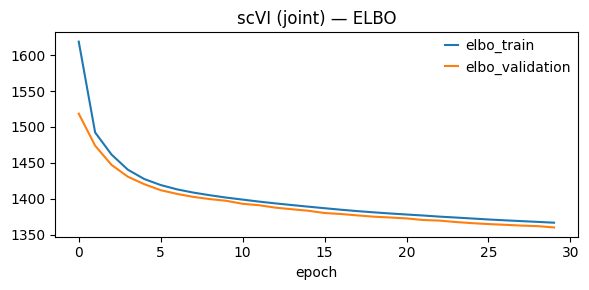

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3))
scvi_model.history["elbo_train"].plot(ax=ax, label="train")
scvi_model.history["elbo_validation"].plot(ax=ax, label="validation")
ax.set(title="scVI (joint) — ELBO"); ax.legend()
plt.tight_layout(); plt.show()

INFO     Training for 15 epochs.                                                                                   


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/15 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=15` reached.


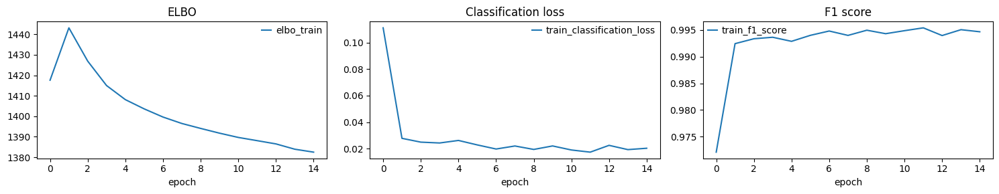

In [ ]:
if USE_SCANVI:
    model = scvi.model.SCANVI.from_scvi_model(scvi_model, unlabeled_category=UNLABELLED, labels_key=LABELS_KEY)
    model.train(
        max_epochs=SCANVI_MAX_EPOCHS,
        n_samples_per_label=N_SAMPLES_PER_LABEL,
        batch_size=BATCH_SIZE,
        datasplitter_kwargs={"num_workers": 16},
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 3))
    model.history["elbo_train"].plot(ax=axes[0], title="ELBO")
    model.history["train_classification_loss"].plot(ax=axes[1], title="Classification loss")
    model.history["train_f1_score"].plot(ax=axes[2], title="F1 score")
    plt.tight_layout(); plt.show()
else:
    model = scvi_model
    print("USE_SCANVI=False: using the unsupervised scVI model.")

LATENT_KEY = "X_scANVI" if USE_SCANVI else "X_scVI"
adata.obsm["X_scVI"] = scvi_model.get_latent_representation()
adata.obsm[LATENT_KEY] = model.get_latent_representation()

sc.pp.neighbors(adata, use_rep=LATENT_KEY)
sc.tl.umap(adata, min_dist=0.3)

In [ ]:
if USE_SCANVI:
    adata.obs["predicted_scanvi"] = model.predict()
    adata.obs["prediction_confidence"] = model.predict(soft=True).max(axis=1).values
    adata.obs["predicted_filtered"] = adata.obs["predicted_scanvi"].astype(str)
    adata.obs.loc[adata.obs["prediction_confidence"] < CONF_THRESHOLD, "predicted_filtered"] = "Low_confidence"

    n_high = (adata.obs["prediction_confidence"] >= CONF_THRESHOLD).sum()
    print(f"High confidence (>= {CONF_THRESHOLD}): {n_high}/{adata.n_obs} ({100 * n_high / adata.n_obs:.1f}%)")
    print(pd.crosstab(adata.obs["predicted_scanvi"], adata.obs["dataset"]))

High confidence (>= 0.8): 393201/413630 (95.1%)
dataset                 HD  HD_deepdive  nucseq  slidetags
predicted_scanvi                                          
-Low_quality          4358         6489    7827      15008
-Mito_cluster_patch    908          213     977       2737
-Phase_D              4566         5641     206        718
-fake_phase_D         1386         8260      89        478
Matrix_D1            61784        28244   10308      30601
Matrix_D2            57227        19177   10528      33415
Patch_D1             24066        10501    5302      15447
Patch_D2             16190         5234    4018      11749
TAFA1                  114          155    1059       8650


In [ ]:
model.save(f"{OUT_DIR}/model/", overwrite=True)
adata.write(f"{OUT_DIR}/adata_joint_hvg.h5ad")
print(f"Model and adata saved to {OUT_DIR}")

... storing 'celltype_scanvi' as categorical
... storing 'predicted_scanvi' as categorical
... storing 'predicted_filtered' as categorical


Model and adata saved to /home/gdallagl/myworkdir/XDP/data/_old/MSN_scVI_joint/full


## 7 · Validate predictions against each dataset's own `ct_for_deg`

Rows = own label, columns = scANVI prediction (row-normalized). Accuracy is computed only on rows whose own label is in `SCANVI_LABELS`.
- Datasets in `LABEL_HOLDOUT_DATASETS`: their labels were never seen → **unbiased** transfer accuracy.
- Other datasets: those labels were used for training → accuracy is optimistic (self-prediction).
- Rows for labels outside `SCANVI_LABELS` (e.g. `TAFA1`, `-Low_quality`) show where those populations land.

=== HD [trained on (optimistic)]: accuracy on SCANVI_LABELS = 0.8786 (170599 cells) ===


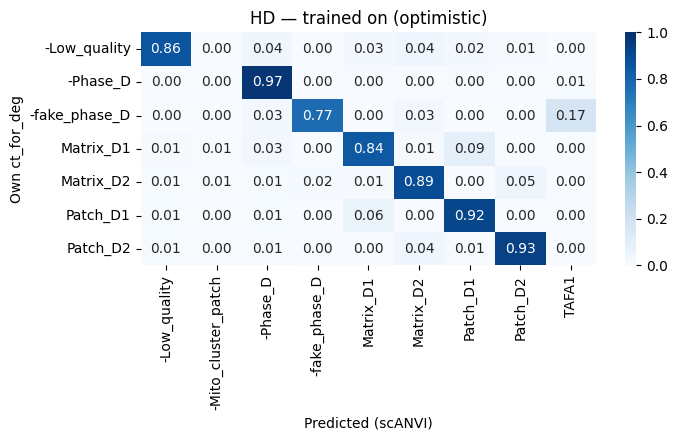

=== HD_deepdive [trained on (optimistic)]: accuracy on SCANVI_LABELS = 0.7994 (83914 cells) ===


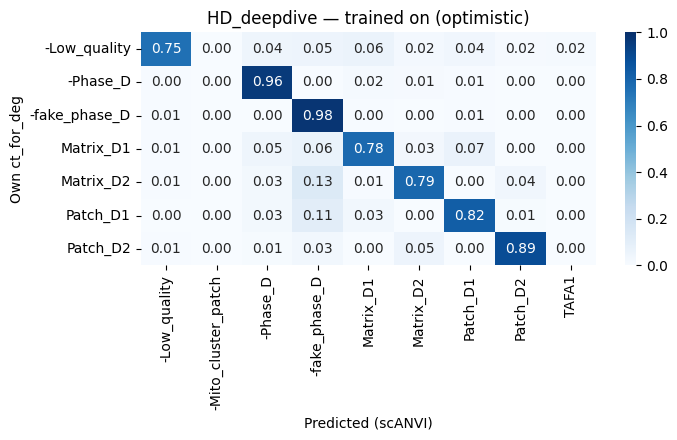

=== nucseq [trained on (optimistic)]: accuracy on SCANVI_LABELS = 0.8404 (40314 cells) ===


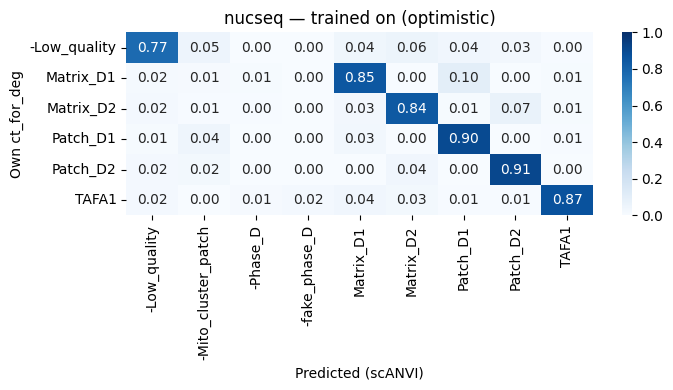

=== slidetags [trained on (optimistic)]: accuracy on SCANVI_LABELS = 0.8410 (118803 cells) ===


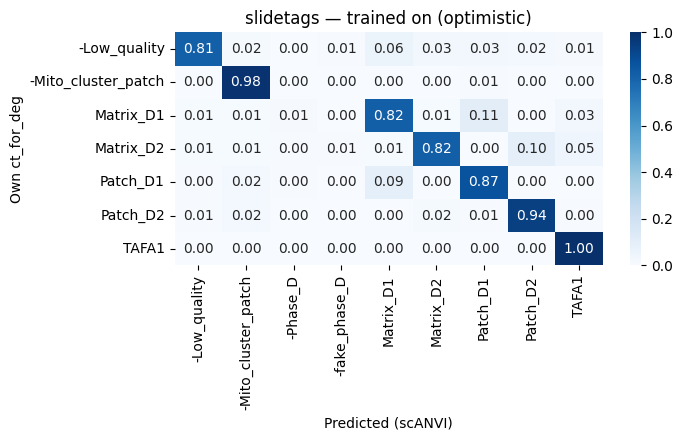

In [ ]:
if USE_SCANVI:
    for name in adata.obs["dataset"].cat.categories:
        o = adata.obs[adata.obs["dataset"] == name]
        own, pred = o[TRAIN_LABEL_COL].astype(str), o["predicted_scanvi"].astype(str)
        scored = own.isin(SCANVI_LABELS)
        kind = "held out (unbiased)" if name in LABEL_HOLDOUT_DATASETS else "trained on (optimistic)"
        print(f"=== {name} [{kind}]: accuracy on SCANVI_LABELS = {(own[scored] == pred[scored]).mean():.4f} ({scored.sum()} cells) ===")

        ct = pd.crosstab(own, pred, normalize="index")
        plt.figure(figsize=(1 + 0.7 * ct.shape[1], 1 + 0.5 * ct.shape[0]))
        sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
        plt.xlabel("Predicted (scANVI)"); plt.ylabel(f"Own {TRAIN_LABEL_COL}")
        plt.title(f"{name} — {kind}")
        plt.tight_layout(); plt.show()

## 8 · Joint visualization

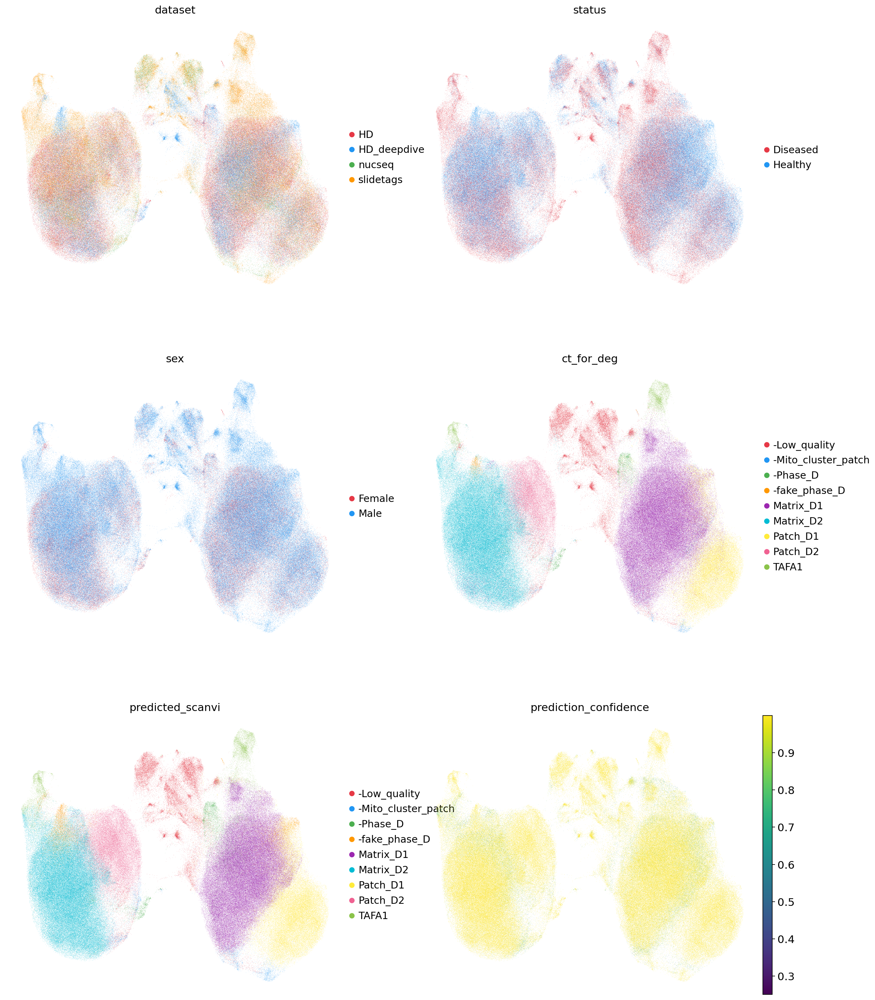

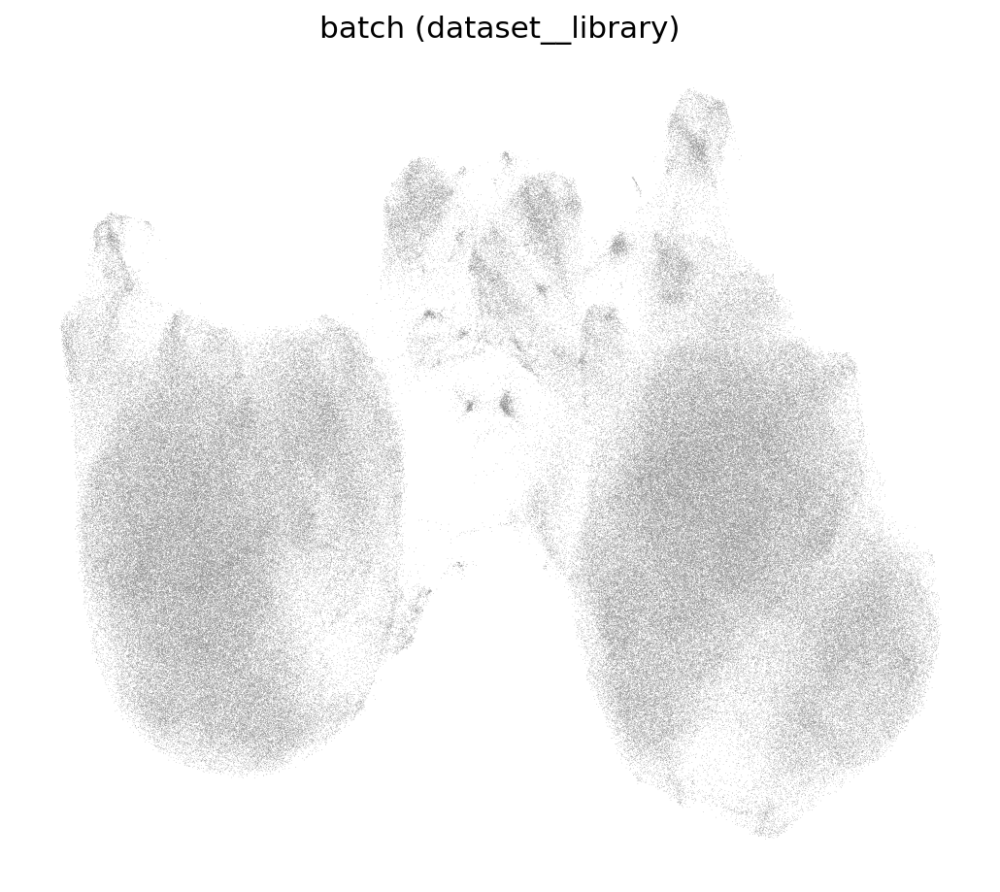

In [ ]:
sc.settings.set_figure_params(figsize=(8, 7))
color = ["dataset", "status", "sex", TRAIN_LABEL_COL] + (["predicted_scanvi", "prediction_confidence"] if USE_SCANVI else [])
sc.pl.umap(adata, color=color, ncols=2, frameon=False, palette=lmu.custom_palette)
sc.pl.umap(adata, color="batch", frameon=False, legend_loc=None, title="batch (dataset__library)")

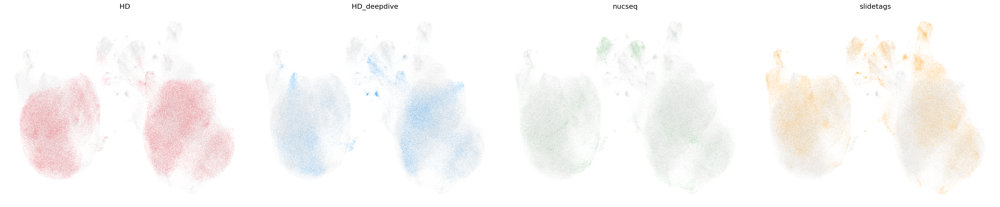

In [ ]:
# each dataset on its own, on the shared embedding: good mixing = each dataset covers the same territory
fig, axes = plt.subplots(1, adata.obs["dataset"].nunique(), figsize=(7 * adata.obs["dataset"].nunique(), 6))
for ax, name in zip(axes, adata.obs["dataset"].cat.categories):
    sc.pl.umap(adata, color="dataset", groups=[name], ax=ax, show=False, frameon=False, title=name, legend_loc=None)
plt.tight_layout(); plt.show()

In [ ]:
adata.obs.columns

Index(['Neighborhood_name', 'Neighborhood_bootstrapping_probability',
       'Neighborhood_aggregate_probability', 'Class_name',
       'Class_bootstrapping_probability', 'Class_aggregate_probability',
       'Subclass_name', 'Subclass_bootstrapping_probability',
       'Subclass_aggregate_probability', 'Group_name',
       'Group_bootstrapping_probability', 'Group_aggregate_probability',
       'Cluster_label', 'Cluster_name', 'Cluster_alias',
       'Cluster_bootstrapping_probability', 'mapping_coupling_for_zoning',
       'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones',
       'zone_4', 'zone_4_probability', 'n_genes_by_counts',
       'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts',
       'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt',
       'leiden_0.1_all_cells', 'leiden_0.5_all_cells', 'leiden_0.07_all_cells',
       'ct_for_deg', 'is_neuron', 'spatial_x', 'spatial_y', 'dataset',
       'donor_id_unified', 'batch', 'status', 'is_d

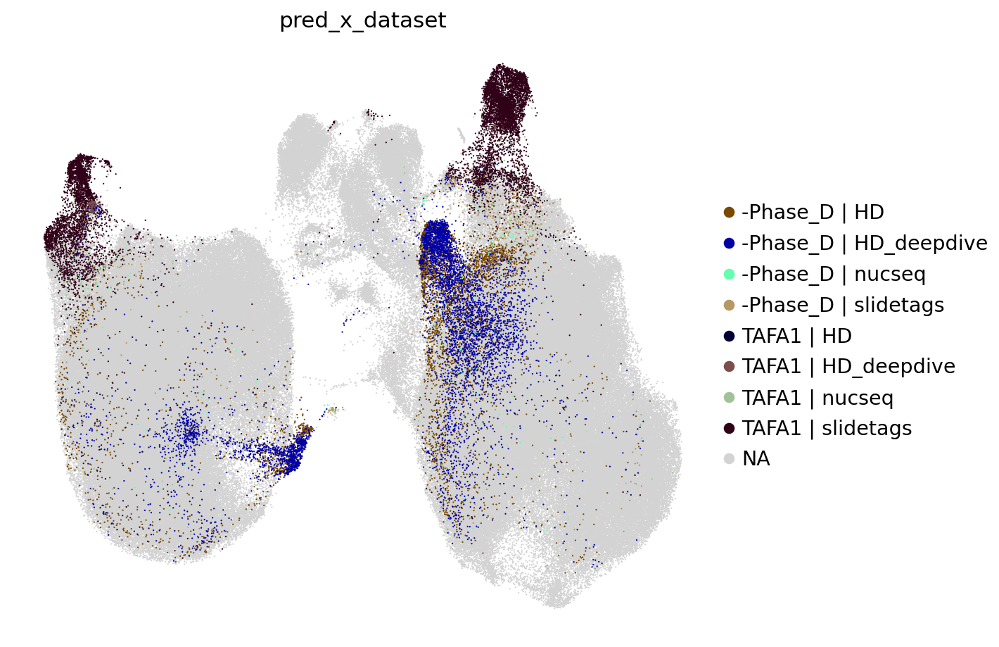

In [ ]:
# colour by scANVI-predicted cell type x dataset, highlighting only the selected cell types
CT_TO_SHOW = ["-Phase_D", "TAFA1"]

adata.obs["pred_x_dataset"] = (
    adata.obs["predicted_scanvi"].astype(str) + " | " + adata.obs["dataset"].astype(str)
).astype("category")

groups = [g for g in adata.obs["pred_x_dataset"].cat.categories if g.split(" | ")[0] in CT_TO_SHOW]
sc.pl.umap(adata, color="pred_x_dataset", groups=groups, frameon=False, s=4)


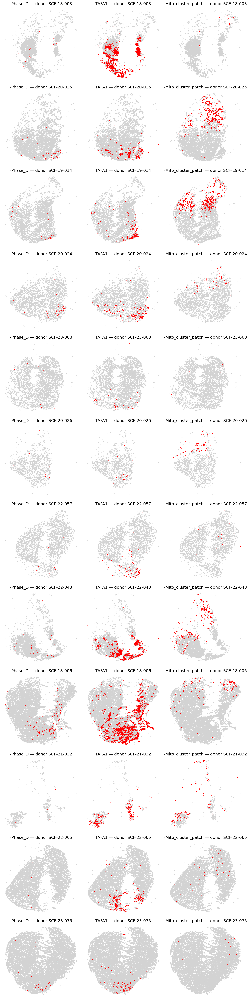

In [ ]:
# SlideTags: grid of donors (rows) x selected predicted cell types (columns), selected type in red
CT_SELECTED = ["-Phase_D", "TAFA1", "-Mito_cluster_patch"]

if USE_SCANVI:
    is_st = adata.obs["dataset"] == "slidetags"
    donors = adata.obs.loc[is_st, "donor_id_unified"].unique()
    fig, axes = plt.subplots(len(donors), len(CT_SELECTED),
                             figsize=(4 * len(CT_SELECTED), 4 * len(donors)), squeeze=False)

    for i, d in enumerate(donors):
        tmp = adata[is_st & (adata.obs["donor_id_unified"] == d)].copy()
        tmp.obsm["spatial"] = tmp.obs[["spatial_x", "spatial_y"]].to_numpy()
        for j, ct in enumerate(CT_SELECTED):
            lab = np.where(tmp.obs["predicted_scanvi"].astype(str) == ct, ct, "other")
            tmp.obs["selected"] = pd.Categorical(lab, categories=[ct, "other"])
            tmp.uns["selected_colors"] = ["red", "lightgrey"]
            sc.pl.embedding(tmp, basis="spatial", color="selected", groups=[ct], frameon=False,
                            title=f"{ct} — donor {d}", size=30, ax=axes[i, j], show=False, legend_loc=None)

    plt.tight_layout()
    plt.show()


... storing 'highlight_shared_donor' as categorical


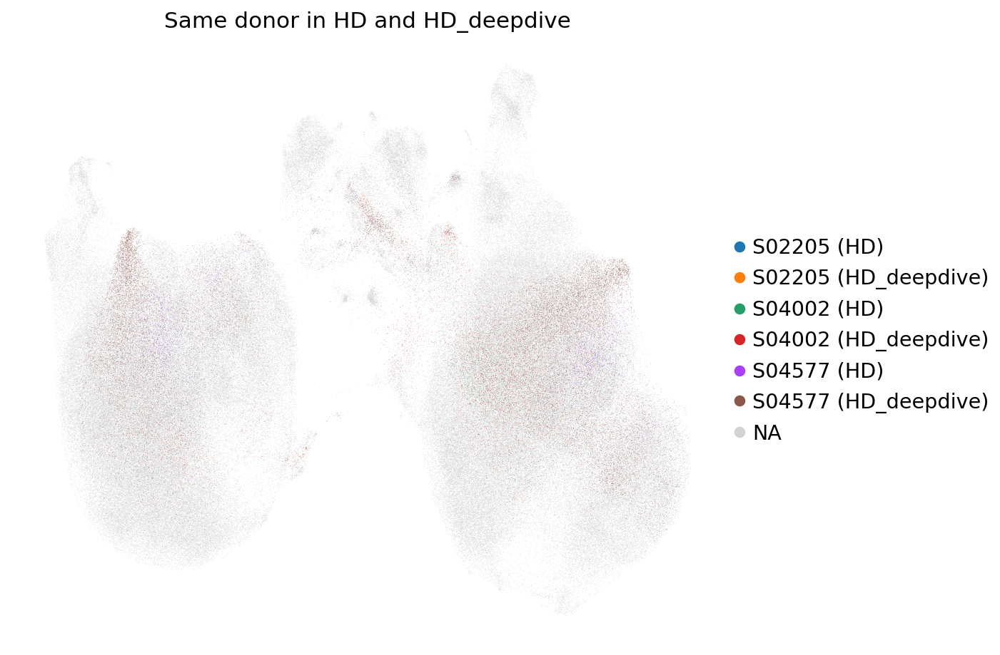

... storing 'highlight_shared_donor' as categorical


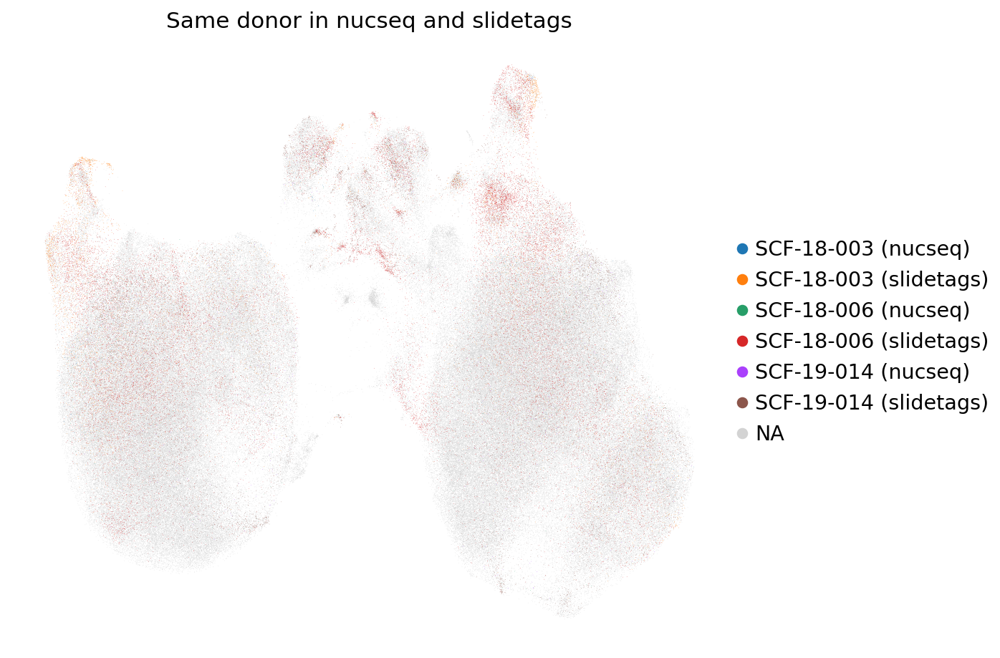

In [ ]:
# Donor harmonization sanity check (Section 4): the same donor's cells from two datasets should overlap
for (a, b), donors in shared_donors.items():
    example = donors[:3]
    in_pair = adata.obs["dataset"].isin([a, b]) & adata.obs["donor_id_unified"].isin(example)
    adata.obs["highlight_shared_donor"] = np.where(
        in_pair, adata.obs["donor_id_unified"].astype(str) + " (" + adata.obs["dataset"].astype(str) + ")", "other")
    sc.pl.umap(
        adata, color="highlight_shared_donor",
        groups=[d for d in adata.obs["highlight_shared_donor"].unique() if d != "other"],
        frameon=False, title=f"Same donor in {a} and {b}",
    )

## 9 · Comparison: Harmony on the same cells

Same cells and genes (`adatas`), integrated with Harmony on PCA instead of scVI. HVGs per `dataset` (as above), Harmony corrects the same technical unit as scVI (`batch`), not donor or sex: Harmony re-centres every level of `vars_use` with no way for biology to push back, and sex is heavily confounded with cohort here (XDP is X-linked, so ~all male; HD is balanced).

In [ ]:
# def run_harmony_integration(adata, hvg_batch_key, harmony_vars_use, n_top_genes=N_TOP_GENES,
#                             n_pcs=50, max_iter_harmony=30, resolutions=[0.1, 0.3, 0.5], seed=42):
#     # same steps as lmu.preprocess_common_pipeline(..., integrate_with_harmony=True), but with the HVG
#     # batch_key (single column) decoupled from Harmony's vars_use (may be a list of columns)
#     import harmonypy
#     lmu.set_global_seeds(seed)

#     adata.X = adata.layers["counts"].copy()
#     sc.pp.normalize_total(adata, target_sum=1e4)
#     sc.pp.log1p(adata)
#     adata.layers["log1p_norm"] = adata.X.copy()

#     sc.pp.highly_variable_genes(adata, n_top_genes=n_top_genes, flavor="seurat_v3", layer="counts", batch_key=hvg_batch_key)

#     adata_hvg = adata[:, adata.var["highly_variable"]].copy()
#     sc.pp.scale(adata_hvg, max_value=10)
#     sc.tl.pca(adata_hvg, svd_solver="randomized", n_comps=n_pcs, random_state=seed)
#     adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"]
#     adata.uns["pca"] = adata_hvg.uns["pca"]
#     del adata_hvg

#     ho = harmonypy.run_harmony(adata.obsm["X_pca"], adata.obs, vars_use=harmony_vars_use, max_iter_harmony=max_iter_harmony)
#     Z = ho.Z_corr
#     adata.obsm["X_pca_harmony"] = Z.T if Z.shape[0] != adata.n_obs else Z

#     sc.pp.neighbors(adata, use_rep="X_pca_harmony", n_pcs=n_pcs, random_state=seed)
#     sc.tl.umap(adata, random_state=seed)
#     for r in resolutions:
#         sc.tl.leiden(adata, resolution=r, key_added=f"leiden_{r}_harmony", flavor="igraph", n_iterations=2, random_state=seed)

#     adata.X = adata.layers["counts"].copy()  # raw counts back in X
#     return adata


# adata_harmony = anndata.concat(adatas, join="inner", index_unique="-", merge="first")
# adata_harmony = run_harmony_integration(adata_harmony, hvg_batch_key="dataset", harmony_vars_use=["batch"])

# sc.pl.umap(adata_harmony, color=["dataset", TRAIN_LABEL_COL, "status", "sex", "leiden_0.5_harmony"],
#            ncols=2, frameon=False, palette=lmu.custom_palette)

In [ ]:
# sc.pl.umap(adata_harmony, color=["leiden_0.1_harmony", "leiden_0.3_harmony", "leiden_0.5_harmony"],
#            ncols=2, frameon=False, palette=lmu.custom_palette, legend_loc="on data")
# sc.pl.umap(adata_harmony, color=TRAIN_LABEL_COL, groups=["-Phase_D"], frameon=False, palette=lmu.custom_palette)
# sc.pl.umap(adata_harmony, color=["ENSG00000147889"], frameon=False, vmax=2, title="CDKN2A")

In [ ]:
# # Wilcoxon markers for chosen Harmony clusters (cluster ids change between runs -- set them after looking at the UMAP)
# from utils import preprocessing

# res = preprocessing.rank_markers_per_cluster(adata_harmony, "leiden_0.5_harmony", layer="log1p_norm", n_genes=50, markers=None,
#                                              groups=["10", "8", "9"])
# for cluster, df in res.items():
#     print(f"Cluster {cluster}:")
#     display(df.merge(adata_harmony.var[["gene_symbol"]], left_on="names", right_index=True, how="left").head(30))

## 10 · Save a light adata for plotting

No counts: only obs metadata (own labels, predictions, confidence, donor, batch, status, spatial_x/y, …), the embeddings (scVI/scANVI latent, scVI UMAP, Harmony UMAP), the Harmony Leiden clusters and the plot colours.
Reload with `sc.read_h5ad(...)` and plot with `sc.pl.embedding(adata_min, basis="X_umap", ...)` / `basis="X_umap_harmony"`.

In [ ]:
OUT_DIR

NameError: name 'OUT_DIR' is not defined

In [ ]:
# ── light adata: obs + embeddings, no counts ──
adata_min = anndata.AnnData(obs=adata.obs.copy())
for key in ["X_umap", "X_scVI", LATENT_KEY]:
    adata_min.obsm[key] = adata.obsm[key]
adata_min.uns = {k: v for k, v in adata.uns.items() if k.endswith("_colors")}

# # Harmony (Section 9) was run on the same cells with the same obs_names
# harmony_cols = [c for c in adata_harmony.obs.columns if c.startswith("leiden_") and c.endswith("_harmony")]
# adata_min.obs[harmony_cols] = adata_harmony.obs.loc[adata_min.obs_names, harmony_cols]
# adata_min.obsm["X_umap_harmony"] = adata_harmony[adata_min.obs_names].obsm["X_umap"]

# concat(join="inner") kept only the obs columns shared by ALL datasets -> add back every original obs column
# (donor id, QC metrics, ...) from each dataset, NaN where a dataset doesn't have it
full_obs = pd.concat([a.obs.set_axis(a.obs_names + "-" + name) for name, a in adatas.items()], join="outer")
extra = full_obs.drop(columns=adata_min.obs.columns, errors="ignore").reindex(adata_min.obs_names)
adata_min.obs = pd.concat([adata_min.obs, extra], axis=1)
for c in adata_min.obs.columns:   # object columns mixing str/numbers/NaN can't be written to h5ad -> categorical of strings
    if adata_min.obs[c].dtype == object:
        col = adata_min.obs[c]
        adata_min.obs[c] = col.where(col.isna(), col.astype(str)).astype("category")

adata_min.write(f"{OUT_DIR}/adata_joint_minimal.h5ad")
print(adata_min)
print(f"Saved to {OUT_DIR}/adata_joint_minimal.h5ad")

# ── full adata: same obs + embeddings, WITH raw counts for all COMMON_GENES (not only the HVGs) ──
adata_counts = anndata.concat(adatas, join="inner", index_unique="-", merge="first")
adata_counts = adata_counts[adata_min.obs_names].copy()      # same cells, same order as adata_min
del adata_counts.layers["counts"]                            # X already holds the raw counts, don't store them twice
adata_counts.obs = adata_min.obs.copy()
for key in adata_min.obsm:
    adata_counts.obsm[key] = adata_min.obsm[key]
adata_counts.uns = dict(adata_min.uns)
adata_counts.var["highly_variable"] = adata_counts.var_names.isin(adata.var_names)   # genes used for scVI

adata_counts.write(f"{OUT_DIR}/adata_joint_counts.h5ad", compression="gzip")
print(adata_counts)
print(f"Saved to {OUT_DIR}/adata_joint_counts.h5ad")


/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


AnnData object with n_obs × n_vars = 413630 × 0
    obs: 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'leiden_0.1_all_cells', 'leiden_0.5_all_cells', 'leiden_0.07_all_cells', 'ct_for_deg', 'is_neuron', 'spatial_x', 'spatial_y', 'dataset', 'donor_id_unified', 'batch', 'status', 'is_diseased', 'sex', 'celltype_scanvi', '_scvi_batch

In [ ]:
stop

NameError: name 'stop' is not defined

In [ ]:
adata_min = sc.read_h5ad(f"{OUT_DIR}/adata_joint_minimal.h5ad")

In [ ]:
adata_min

AnnData object with n_obs × n_vars = 413630 × 0
    obs: 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'leiden_0.1_all_cells', 'leiden_0.5_all_cells', 'leiden_0.07_all_cells', 'ct_for_deg', 'is_neuron', 'spatial_x', 'spatial_y', 'dataset', 'donor_id_unified', 'batch', 'status', 'is_diseased', 'sex', 'celltype_scanvi', '_scvi_batch

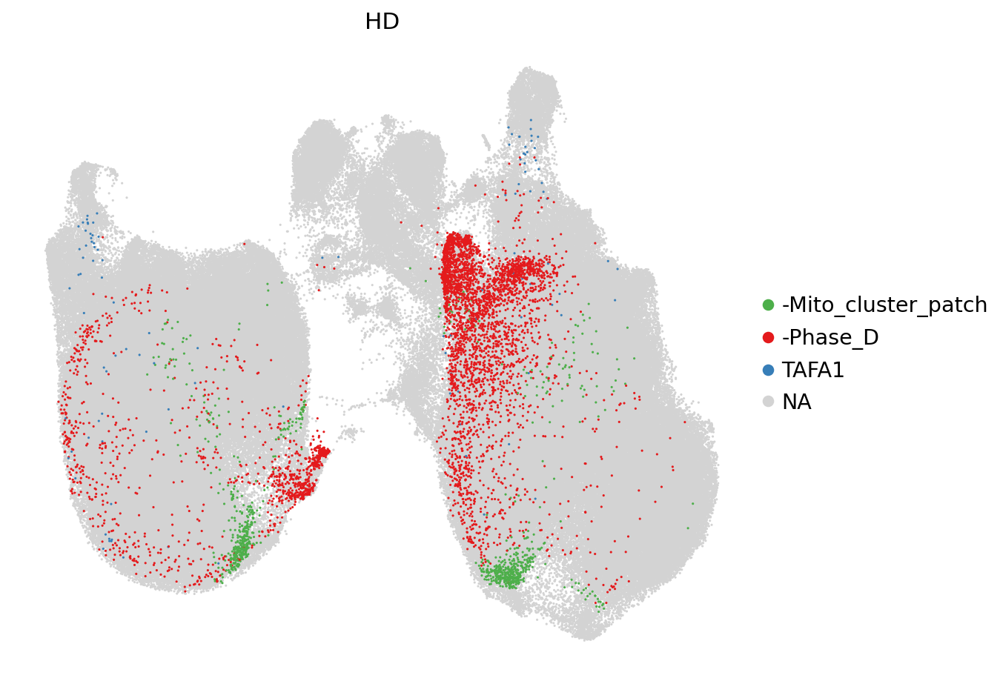

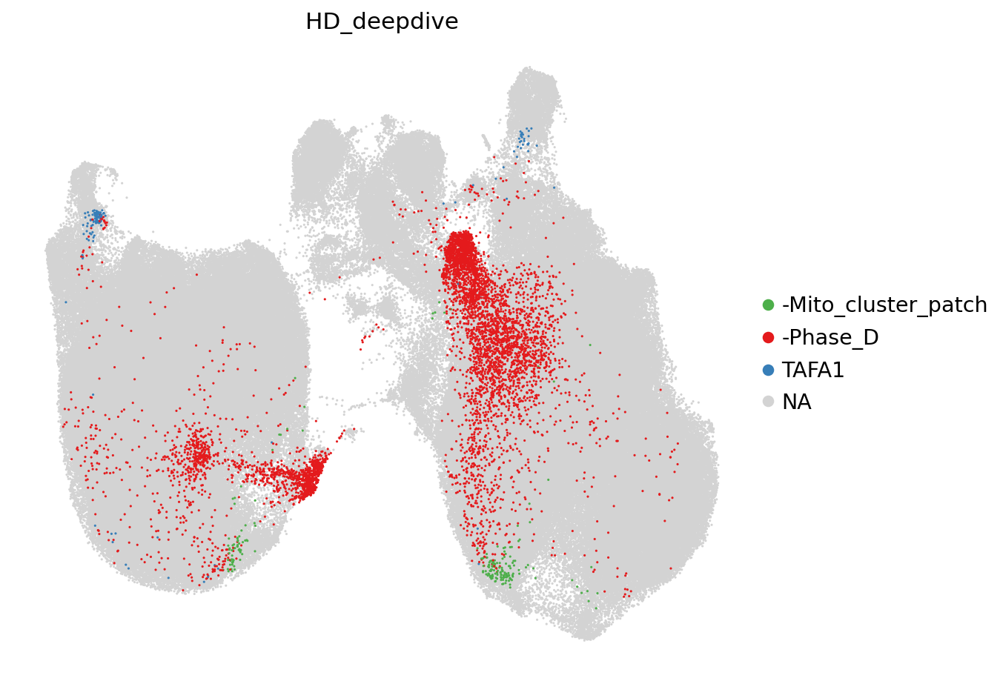

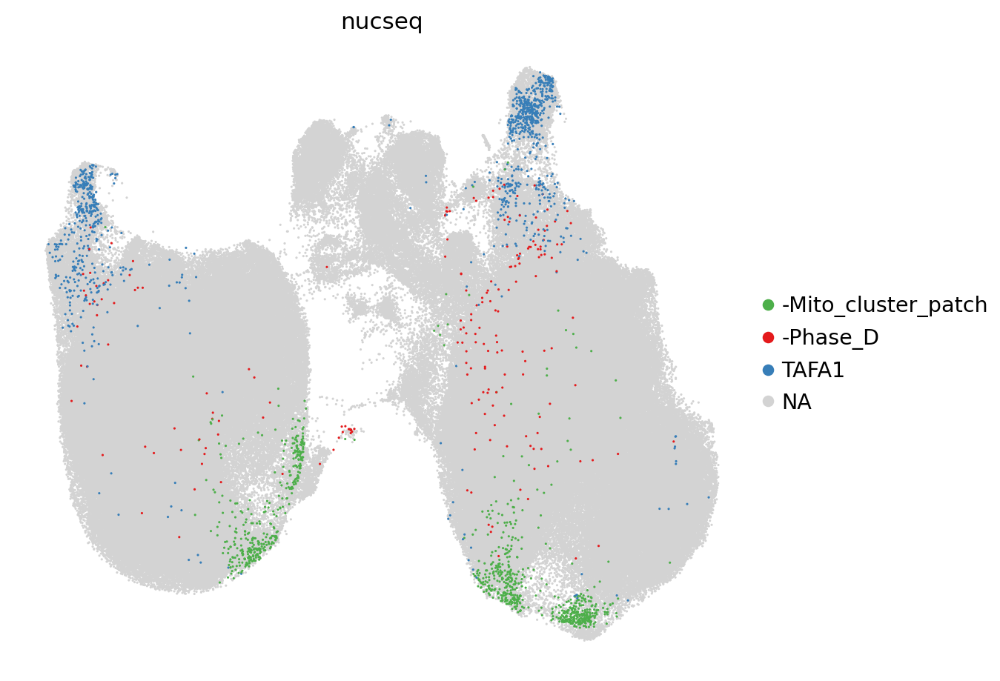

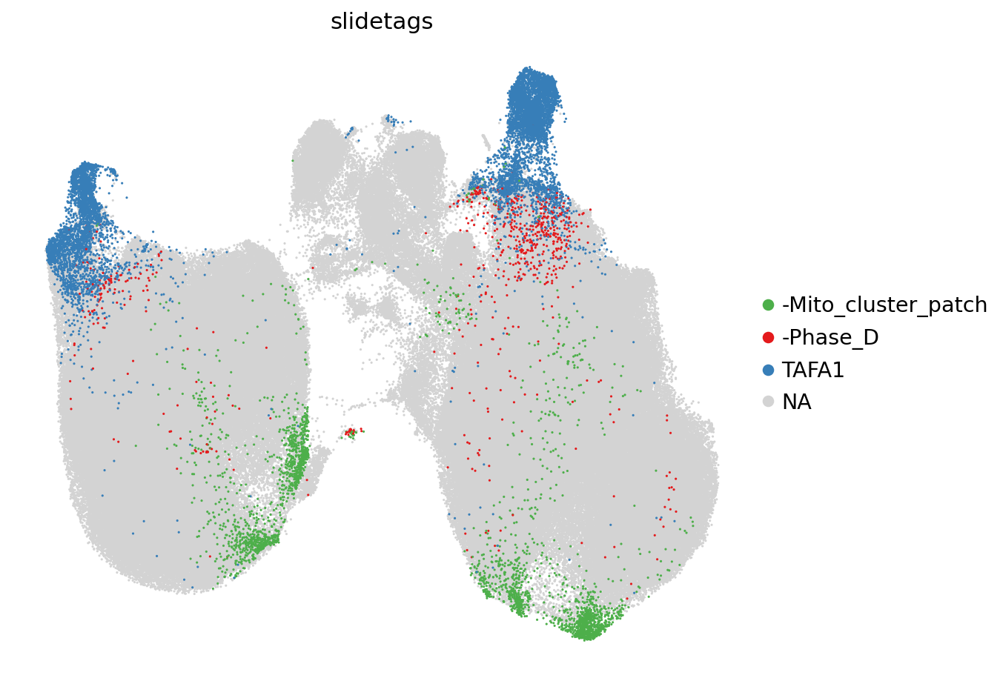

In [ ]:
# colour by scANVI-predicted cell type, one UMAP per dataset, same colours in every plot
CT_TO_SHOW = ["-Phase_D", "TAFA1", "-Mito_cluster_patch"]
CT_COLORS  = ["#e41a1c", "#377eb8", "#4daf4a"]   # one colour per CT_TO_SHOW entry, same order

for name in adata_min.obs["dataset"].cat.categories:
    in_ds = adata_min.obs["dataset"] == name
    lab = adata_min.obs["predicted_scanvi"].astype(str)
    lab = lab.where(in_ds & lab.isin(CT_TO_SHOW), "other")   # everything else -> grey
    adata_min.obs["pred_shown"] = pd.Categorical(lab, categories=CT_TO_SHOW + ["other"])
    adata_min.uns["pred_shown_colors"] = CT_COLORS + ["lightgrey"]

    sc.pl.umap(adata_min, color="pred_shown", groups=CT_TO_SHOW, frameon=False, s=8, title=name)
    adata_min.obs.drop(columns="pred_shown", inplace=True)
    adata_min.uns.pop("pred_shown_colors", None)


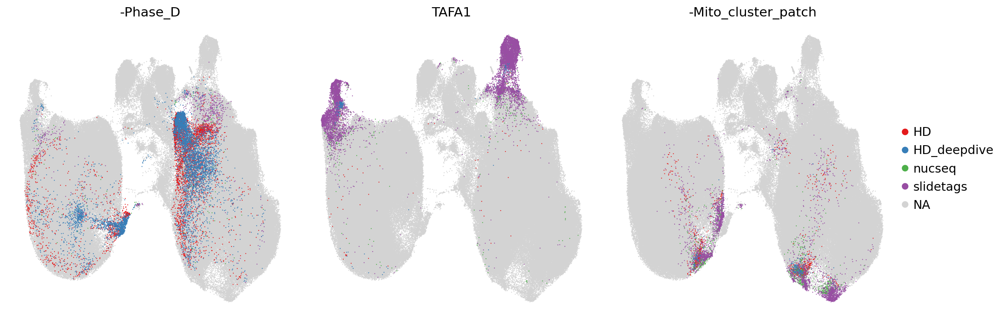

In [ ]:
# one UMAP per scANVI-predicted cell type, coloured by dataset (same dataset colours in every plot)
CT_TO_SHOW  = ["-Phase_D", "TAFA1", "-Mito_cluster_patch"]
DATASETS_SHOWN = list(adata_min.obs["dataset"].cat.categories)
DS_COLORS   = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3"]   # one colour per dataset, same order as DATASETS_SHOWN

fig, axes = plt.subplots(1, len(CT_TO_SHOW), figsize=(5 * len(CT_TO_SHOW), 5), squeeze=False)
for j, ct in enumerate(CT_TO_SHOW):
    is_ct = adata_min.obs["predicted_scanvi"].astype(str) == ct
    lab = adata_min.obs["dataset"].astype(str).where(is_ct, "other")   # other cell types -> grey
    adata_min.obs["ds_shown"] = pd.Categorical(lab, categories=DATASETS_SHOWN + ["other"])
    adata_min.uns["ds_shown_colors"] = DS_COLORS[:len(DATASETS_SHOWN)] + ["lightgrey"]

    sc.pl.umap(adata_min, color="ds_shown", groups=DATASETS_SHOWN, frameon=False, s=4, title=ct,
               ax=axes[0, j], show=False, legend_loc="right margin" if j == len(CT_TO_SHOW) - 1 else None)

adata_min.obs.drop(columns="ds_shown", inplace=True)
adata_min.uns.pop("ds_shown_colors", None)
plt.tight_layout()
plt.show()
